In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_excel('/content/Online Retail.xlsx')

In [3]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [4]:
df.shape

(541909, 8)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [6]:
df.isna().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [7]:
df[df['Description'].isna()]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
535322,581199,84581,NaN,-2,2011-12-07 18:26:00,0.0,NaN,United Kingdom
535326,581203,23406,NaN,15,2011-12-07 18:31:00,0.0,NaN,United Kingdom
535332,581209,21620,NaN,6,2011-12-07 18:35:00,0.0,NaN,United Kingdom
536981,581234,72817,NaN,27,2011-12-08 10:33:00,0.0,NaN,United Kingdom


from the above table we observe that null values are present on the same row and same column for both customer ID and description. so we can remove the null values

In [8]:
df=df.dropna()

In [9]:
df.isna().sum()

,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0


In [10]:
df.shape

(406829, 8)

In [11]:
df.duplicated().sum()

np.int64(5225)

In [12]:
df=df.drop_duplicates()

In [13]:
df.shape

(401604, 8)

In [14]:
df['Country'].unique()

array(['United Kingdom', 'France', 'Australia', 'Netherlands', 'Germany',
       'Norway', 'EIRE', 'Switzerland', 'Spain', 'Poland', 'Portugal',
       'Italy', 'Belgium', 'Lithuania', 'Japan', 'Iceland',
       'Channel Islands', 'Denmark', 'Cyprus', 'Sweden', 'Austria',
       'Israel', 'Finland', 'Greece', 'Singapore', 'Lebanon',
       'United Arab Emirates', 'Saudi Arabia', 'Czech Republic', 'Canada',
       'Unspecified', 'Brazil', 'USA', 'European Community', 'Bahrain',
       'Malta', 'RSA'], dtype=object)

In [15]:
df[df['Country']=='European Community']

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
168149,551013,22839,3 TIER CAKE TIN GREEN AND CREAM,1,2011-04-26 10:54:00,14.95,15108.0,European Community
168150,551013,22840,ROUND CAKE TIN VINTAGE RED,2,2011-04-26 10:54:00,7.95,15108.0,European Community
168151,551013,22841,ROUND CAKE TIN VINTAGE GREEN,2,2011-04-26 10:54:00,7.95,15108.0,European Community
168152,551013,22457,NATURAL SLATE HEART CHALKBOARD,6,2011-04-26 10:54:00,2.95,15108.0,European Community
168153,551013,22314,OFFICE MUG WARMER CHOC+BLUE,6,2011-04-26 10:54:00,2.95,15108.0,European Community
...,...,...,...,...,...,...,...,...
273232,560783,21098,CHRISTMAS TOILET ROLL,12,2011-07-21 10:24:00,1.25,15108.0,European Community
273233,560783,72807C,SET/3 VANILLA SCENTED CANDLE IN BOX,12,2011-07-21 10:24:00,4.25,15108.0,European Community
273234,560783,85036B,CHOCOLATE 1 WICK MORRIS BOX CANDLE,12,2011-07-21 10:24:00,4.25,15108.0,European Community
273235,560783,85035C,ROSE 3 WICK MORRIS BOX CANDLE,8,2011-07-21 10:24:00,4.25,15108.0,European Community


In [16]:
df[df['Country']=='Unspecified']

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
152712,549687,20685,DOORMAT RED RETROSPOT,2,2011-04-11 13:29:00,7.95,12363.0,Unspecified
152713,549687,22691,DOORMAT WELCOME SUNRISE,2,2011-04-11 13:29:00,7.95,12363.0,Unspecified
152714,549687,48116,DOORMAT MULTICOLOUR STRIPE,2,2011-04-11 13:29:00,7.95,12363.0,Unspecified
152715,549687,21213,PACK OF 72 SKULL CAKE CASES,24,2011-04-11 13:29:00,0.55,12363.0,Unspecified
152716,549687,21977,PACK OF 60 PINK PAISLEY CAKE CASES,24,2011-04-11 13:29:00,0.55,12363.0,Unspecified
...,...,...,...,...,...,...,...,...
308810,564051,23007,SPACEBOY BABY GIFT SET,1,2011-08-22 13:32:00,16.95,14265.0,Unspecified
308811,564051,21833,CAMOUFLAGE LED TORCH,12,2011-08-22 13:32:00,1.69,14265.0,Unspecified
308812,564051,23081,GREEN METAL BOX ARMY SUPPLIES,2,2011-08-22 13:32:00,8.25,14265.0,Unspecified
308813,564051,23046,PAPER LANTERN 9 POINT DELUXE STAR,2,2011-08-22 13:32:00,6.65,14265.0,Unspecified


In [17]:
df=df[df['Country']!='Unspecified']

In [18]:
df['Country'].unique()

array(['United Kingdom', 'France', 'Australia', 'Netherlands', 'Germany',
       'Norway', 'EIRE', 'Switzerland', 'Spain', 'Poland', 'Portugal',
       'Italy', 'Belgium', 'Lithuania', 'Japan', 'Iceland',
       'Channel Islands', 'Denmark', 'Cyprus', 'Sweden', 'Austria',
       'Israel', 'Finland', 'Greece', 'Singapore', 'Lebanon',
       'United Arab Emirates', 'Saudi Arabia', 'Czech Republic', 'Canada',
       'Brazil', 'USA', 'European Community', 'Bahrain', 'Malta', 'RSA'],
      dtype=object)

In [19]:
df=df[df['Country']!='European Community']

In [20]:
df['Country'].unique()

array(['United Kingdom', 'France', 'Australia', 'Netherlands', 'Germany',
       'Norway', 'EIRE', 'Switzerland', 'Spain', 'Poland', 'Portugal',
       'Italy', 'Belgium', 'Lithuania', 'Japan', 'Iceland',
       'Channel Islands', 'Denmark', 'Cyprus', 'Sweden', 'Austria',
       'Israel', 'Finland', 'Greece', 'Singapore', 'Lebanon',
       'United Arab Emirates', 'Saudi Arabia', 'Czech Republic', 'Canada',
       'Brazil', 'USA', 'Bahrain', 'Malta', 'RSA'], dtype=object)

In [21]:
df['Description'].unique()

array(['WHITE HANGING HEART T-LIGHT HOLDER', 'WHITE METAL LANTERN',
       'CREAM CUPID HEARTS COAT HANGER', ...,
       'PINK CRYSTAL SKULL PHONE CHARM',
       'CREAM HANGING HEART T-LIGHT HOLDER',
       'PAPER CRAFT , LITTLE BIRDIE'], dtype=object)

In [22]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 401302 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    401302 non-null  object        
 1   StockCode    401302 non-null  object        
 2   Description  401302 non-null  object        
 3   Quantity     401302 non-null  int64         
 4   InvoiceDate  401302 non-null  datetime64[ns]
 5   UnitPrice    401302 non-null  float64       
 6   CustomerID   401302 non-null  float64       
 7   Country      401302 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 27.6+ MB


In [24]:
df=df.drop(columns=['InvoiceNo','StockCode','Description','CustomerID'])

removed unnecessary column from the data

In [25]:
df

,Quantity,InvoiceDate,UnitPrice,Country
0,6,2010-12-01 08:26:00,2.55,United Kingdom
1,6,2010-12-01 08:26:00,3.39,United Kingdom
2,8,2010-12-01 08:26:00,2.75,United Kingdom
3,6,2010-12-01 08:26:00,3.39,United Kingdom
4,6,2010-12-01 08:26:00,3.39,United Kingdom
...,...,...,...,...
541904,12,2011-12-09 12:50:00,0.85,France
541905,6,2011-12-09 12:50:00,2.10,France
541906,4,2011-12-09 12:50:00,4.15,France
541907,4,2011-12-09 12:50:00,4.15,France


In [26]:
df

,Quantity,InvoiceDate,UnitPrice,Country
0,6,2010-12-01 08:26:00,2.55,United Kingdom
1,6,2010-12-01 08:26:00,3.39,United Kingdom
2,8,2010-12-01 08:26:00,2.75,United Kingdom
3,6,2010-12-01 08:26:00,3.39,United Kingdom
4,6,2010-12-01 08:26:00,3.39,United Kingdom
...,...,...,...,...
541904,12,2011-12-09 12:50:00,0.85,France
541905,6,2011-12-09 12:50:00,2.10,France
541906,4,2011-12-09 12:50:00,4.15,France
541907,4,2011-12-09 12:50:00,4.15,France


In [27]:
df['Invoicemonth']=pd.to_datetime(df['InvoiceDate']).dt.month

In [28]:
df['Invoiceyear']=pd.to_datetime(df['InvoiceDate']).dt.year

In [29]:
df

,Quantity,InvoiceDate,UnitPrice,Country,Invoicemonth,Invoiceyear
0,6,2010-12-01 08:26:00,2.55,United Kingdom,12,2010
1,6,2010-12-01 08:26:00,3.39,United Kingdom,12,2010
2,8,2010-12-01 08:26:00,2.75,United Kingdom,12,2010
3,6,2010-12-01 08:26:00,3.39,United Kingdom,12,2010
4,6,2010-12-01 08:26:00,3.39,United Kingdom,12,2010
...,...,...,...,...,...,...
541904,12,2011-12-09 12:50:00,0.85,France,12,2011
541905,6,2011-12-09 12:50:00,2.10,France,12,2011
541906,4,2011-12-09 12:50:00,4.15,France,12,2011
541907,4,2011-12-09 12:50:00,4.15,France,12,2011


In [30]:
df=df.drop(columns=['InvoiceDate'])

In [31]:
df['Invoicemonth'].unique()

array([12,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11], dtype=int32)

In [32]:
df['Invoicemonth']=df['Invoicemonth'].replace({1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'Jun',7:'Jul',8:'Aug',9:'Sep',
                            10:'Oct',11:'Nov',12:'Dec'})

In [33]:
df

,Quantity,UnitPrice,Country,Invoicemonth,Invoiceyear
0,6,2.55,United Kingdom,Dec,2010
1,6,3.39,United Kingdom,Dec,2010
2,8,2.75,United Kingdom,Dec,2010
3,6,3.39,United Kingdom,Dec,2010
4,6,3.39,United Kingdom,Dec,2010
...,...,...,...,...,...
541904,12,0.85,France,Dec,2011
541905,6,2.10,France,Dec,2011
541906,4,4.15,France,Dec,2011
541907,4,4.15,France,Dec,2011


In [34]:
df['Invoiceyear'].unique()

array([2010, 2011], dtype=int32)

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 401302 entries, 0 to 541908
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Quantity      401302 non-null  int64  
 1   UnitPrice     401302 non-null  float64
 2   Country       401302 non-null  object 
 3   Invoicemonth  401302 non-null  object 
 4   Invoiceyear   401302 non-null  int32  
dtypes: float64(1), int32(1), int64(1), object(2)
memory usage: 16.8+ MB


In [36]:
df['Invoiceyear']=df['Invoiceyear'].astype('str')

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 401302 entries, 0 to 541908
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Quantity      401302 non-null  int64  
 1   UnitPrice     401302 non-null  float64
 2   Country       401302 non-null  object 
 3   Invoicemonth  401302 non-null  object 
 4   Invoiceyear   401302 non-null  object 
dtypes: float64(1), int64(1), object(3)
memory usage: 18.4+ MB


In [38]:
df['Quantity'].unique()

array([     6,      8,      2,     32,      3,      4,     24,     12,
           48,     18,     20,     36,     80,     64,     10,    120,
           96,     23,      5,      1,     -1,     50,     40,    100,
          192,    432,    144,    288,    -12,    -24,     16,      9,
          128,     25,     30,     28,      7,     72,    200,    600,
          480,     -6,     14,     -2,     -4,     -5,     -7,     -3,
           11,     70,    252,     60,    216,    384,     27,    108,
           52,  -9360,     75,    270,     42,    240,     90,    320,
           17,   1824,    204,     69,    -36,   -192,   -144,    160,
         2880,   1400,     19,     39,    -48,    -50,     56,     13,
         1440,     -8,     15,    720,    -20,    156,    324,     41,
          -10,    -72,    -11,    402,    378,    150,    300,     22,
           34,    408,    972,    208,   1008,     26,   1000,    -25,
         1488,    250,   1394,    400,    110,    -14,     37,    -33,
      

In [39]:
df=df[df['Quantity']>0]

In [46]:
df['Quantity'].unique()

array([    6,     8,     2,    32,     3,     4,    24,    12,    48,
          18,    20,    36,    80,    64,    10,   120,    96,    23,
           5,     1,    50,    40,   100,   192,   432,   144,   288,
          16,     9,   128,    25,    30,    28,     7,    72,   200,
         600,   480,    14,    11,    70,   252,    60,   216,   384,
          27,   108,    52,    75,   270,    42,   240,    90,   320,
          17,  1824,   204,    69,   160,  2880,  1400,    19,    39,
          56,    13,  1440,    15,   720,   156,   324,    41,   402,
         378,   150,   300,    22,    34,   408,   972,   208,  1008,
          26,  1000,  1488,   250,  1394,   400,   110,    37,    78,
          21,   272,    84,    47,  1728,    38,    53,    76,   576,
          29,  2400,   500,   180,   960,  1296,   147,   168,   256,
          54,    31,   860,  1010,  1356,  1284,   186,   114,   360,
        1930,  2000,  3114,  1300,   670,   176,   648,    62, 74215,
          89,    33,

Exploratory Data Analysis

<Axes: xlabel='Invoicemonth', ylabel='UnitPrice'>

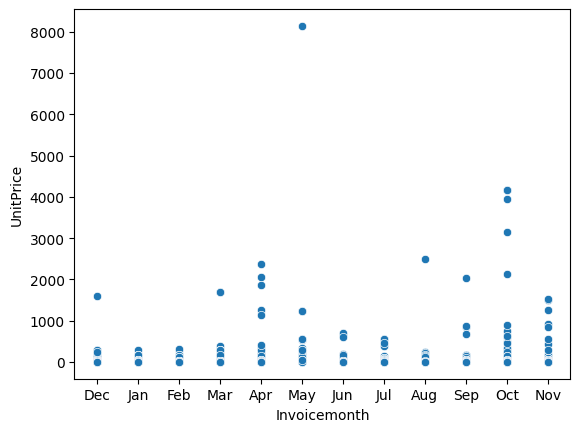

In [41]:
sns.scatterplot(x=df['Invoicemonth'],y=df['UnitPrice'])

<Axes: xlabel='Country'>

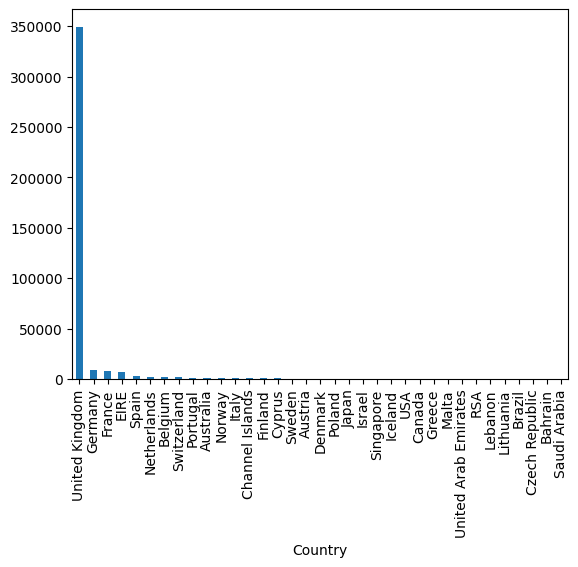

In [51]:
df['Country'].value_counts().plot(kind='bar')

<Axes: xlabel='Quantity', ylabel='UnitPrice'>

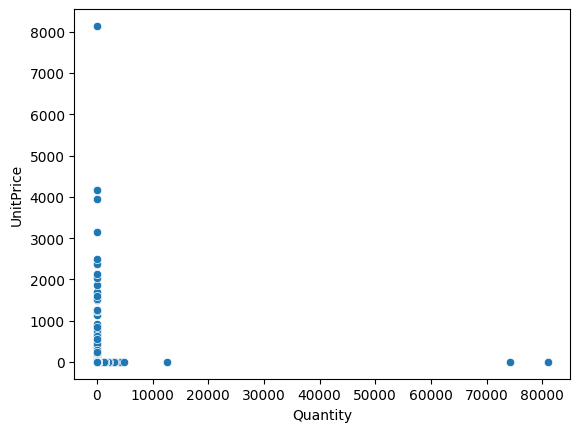

In [42]:
sns.scatterplot(x=df['Quantity'],y=df['UnitPrice'])

<Axes: ylabel='count'>

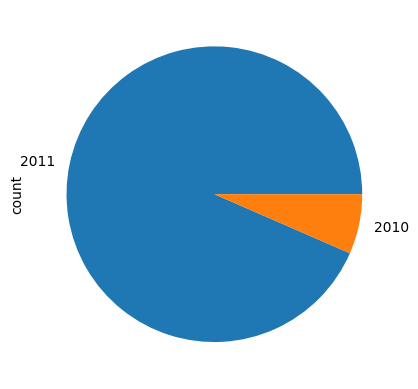

In [43]:
df['Invoiceyear'].value_counts().plot(kind='pie')

<Axes: >

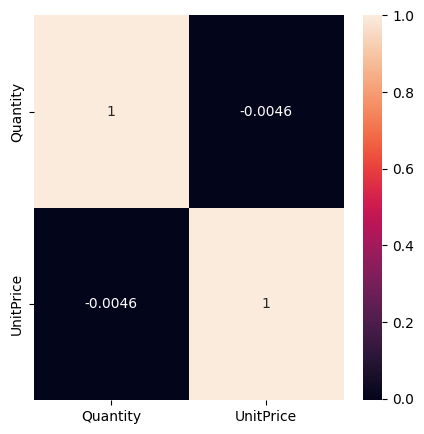

In [44]:
plt.figure(figsize=(5,5))
sns.heatmap(df.select_dtypes(include=np.number).corr(),annot=True)

<Axes: >

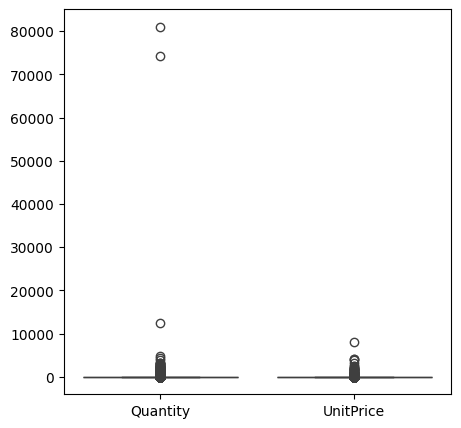

In [48]:
plt.figure(figsize=(5,5))
sns.boxplot(df)